# Day 061 | Neural Network from Scratch (NumPy)

## 100 Days of ML for Geotechnical Engineering
**Phase:** Deep Learning | **Author:** Ripon Chandra Malo | **Date:** YYYY-MM-DD

---

## What We Will Learn Today

| Concept | What It Means | Geotechnical Example |
|---------|--------------|---------------------|
| Neuron | Weighted sum + activation | Combining SPT N-value, depth, water content to estimate strength |
| Forward pass | Input → hidden → output | Soil properties in, UCS prediction out |
| Activation functions | Non-linear transformations | Sigmoid squashes to 0–1, ReLU clips negatives |
| Backpropagation | Compute gradients of the loss | How much each weight contributed to prediction error |
| Gradient descent | Update weights to reduce loss | Iteratively improving UCS predictions |
| Loss function | Measures prediction error | MSE between predicted and measured compressive strength |

---

## Our Geotechnical Problem

We want to predict **Unconfined Compressive Strength (UCS)** of soil from three field/lab properties:

```
Inputs (features):           Output (target):
─────────────────            ─────────────────
  N_value (SPT)              UCS (kPa)
  Depth (m)
  Water content (%)
```

We will build a **2-layer neural network entirely from scratch** using only NumPy — no frameworks.
This helps us understand exactly what PyTorch does under the hood.

### Network Architecture

```
  Input Layer (3)     Hidden Layer (8)      Output Layer (1)
  ┌───────────┐      ┌──────────────┐      ┌─────────────┐
  │ N_value    │────▶│  8 neurons   │────▶│  UCS (kPa)  │
  │ Depth      │────▶│  ReLU activ. │────▶│  Linear     │
  │ Water cont.│────▶│              │────▶│             │
  └───────────┘      └──────────────┘      └─────────────┘
       (3)                 (8)                   (1)
```

---

## Part 1: Generate Synthetic Geotechnical Data

We create 100 synthetic soil samples with known relationships:
- Higher N-value → higher UCS
- Greater depth → higher UCS (more confinement)
- Higher water content → lower UCS (weaker soil)

In [1]:
# ───────────────────────────────────────────────────────
# GENERATE SYNTHETIC SOIL DATA FOR UCS PREDICTION
# ───────────────────────────────────────────────────────

import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

n_samples = 100

# Feature ranges typical for cohesive soils
N_value       = np.random.uniform(5, 40, n_samples)       # SPT blow count
depth         = np.random.uniform(1, 20, n_samples)       # meters
water_content = np.random.uniform(10, 45, n_samples)      # percent

# Synthetic UCS (kPa) — realistic relationship with noise
# UCS increases with N-value and depth, decreases with water content
UCS = (3.5 * N_value
       + 2.0 * depth
       - 1.8 * water_content
       + 50.0
       + np.random.normal(0, 8, n_samples))  # noise

UCS = np.clip(UCS, 10, None)  # UCS must be positive

# Stack into feature matrix: (100, 3)
X = np.column_stack([N_value, depth, water_content])
y = UCS.reshape(-1, 1)  # (100, 1)

print(f"Feature matrix X: {X.shape}")
print(f"Target vector y:  {y.shape}")
print(f"\nFirst 5 samples:")
print(f"{'N_value':>8} {'Depth':>6} {'WC(%)':>6} {'UCS(kPa)':>10}")
print("─" * 34)
for i in range(5):
    print(f"{X[i, 0]:8.1f} {X[i, 1]:6.1f} {X[i, 2]:6.1f} {y[i, 0]:10.1f}")

Feature matrix X: (100, 3)
Target vector y:  (100, 1)

First 5 samples:
 N_value  Depth  WC(%)   UCS(kPa)
──────────────────────────────────
    18.1    1.6   32.5       58.5
    38.3   13.1   12.9      181.6
    30.6    7.0   15.7      160.1
    26.0   10.7   41.4       92.6
    10.5   18.2   31.2       50.7


In [2]:
# ───────────────────────────────────────────────────────
# NORMALIZE THE DATA — Critical for neural networks
# ───────────────────────────────────────────────────────

# Standardize features: zero mean, unit variance
X_mean = X.mean(axis=0)
X_std  = X.std(axis=0)
X_norm = (X - X_mean) / X_std

# Normalize target similarly
y_mean = y.mean()
y_std  = y.std()
y_norm = (y - y_mean) / y_std

print("Normalization statistics:")
print(f"  X mean: {X_mean}")
print(f"  X std:  {X_std}")
print(f"  y mean: {y_mean:.2f}, y std: {y_std:.2f}")
print(f"\nNormalized X range: [{X_norm.min():.2f}, {X_norm.max():.2f}]")
print(f"Normalized y range: [{y_norm.min():.2f}, {y_norm.max():.2f}]")
print()
print("Why normalize? Features have very different scales:")
print(f"  N_value range: {N_value.min():.1f} – {N_value.max():.1f}")
print(f"  Depth range:   {depth.min():.1f} – {depth.max():.1f}")
print(f"  WC range:      {water_content.min():.1f} – {water_content.max():.1f}")
print("Without normalization, large-scale features dominate the gradients.")

Normalization statistics:
  X mean: [21.45632602 10.45880274 28.11604658]
  X std:  [10.35993793  5.54119826 10.21844003]
  y mean: 95.97, y std: 44.38

Normalized X range: [-1.76, 1.75]
Normalized y range: [-1.94, 2.49]

Why normalize? Features have very different scales:
  N_value range: 5.2 – 39.5
  Depth range:   1.1 – 19.7
  WC range:      10.2 – 44.7
Without normalization, large-scale features dominate the gradients.


---

## Part 2: Activation Functions

Activation functions introduce **non-linearity** — without them, stacking layers is just matrix multiplication (linear).

| Function | Formula | Range | Use Case |
|----------|---------|-------|----------|
| Sigmoid | σ(x) = 1 / (1 + e^(-x)) | (0, 1) | Binary classification |
| ReLU | f(x) = max(0, x) | [0, ∞) | Hidden layers (most common) |
| Linear | f(x) = x | (-∞, ∞) | Output layer for regression |

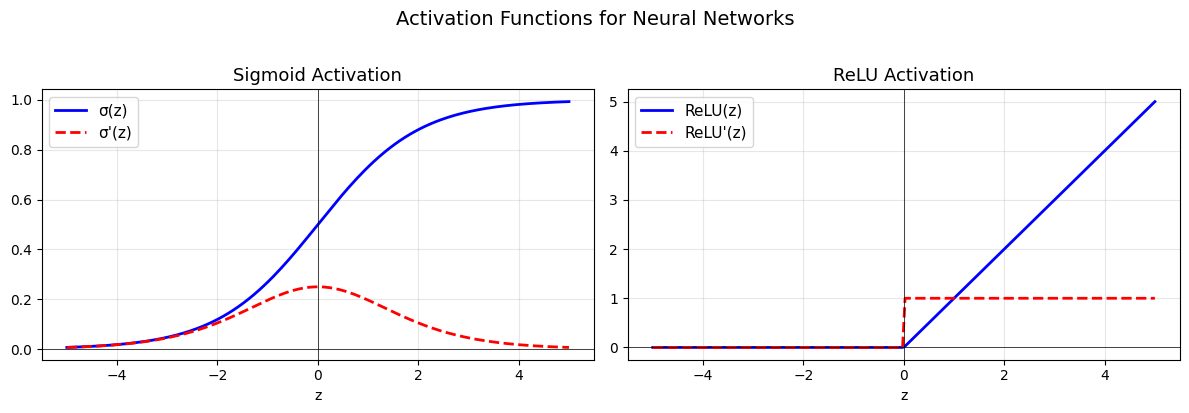

Sigmoid: good for probabilities (0–1 output)
ReLU:    good for hidden layers — fast, avoids vanishing gradient


In [3]:
# ───────────────────────────────────────────────────────
# ACTIVATION FUNCTIONS AND THEIR DERIVATIVES
# ───────────────────────────────────────────────────────

def sigmoid(z):
    """Sigmoid activation: squashes input to (0, 1)."""
    return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))

def sigmoid_derivative(a):
    """Derivative of sigmoid: σ'(z) = σ(z) * (1 - σ(z)).
    Input `a` is the sigmoid output (already activated)."""
    return a * (1.0 - a)

def relu(z):
    """ReLU activation: max(0, z)."""
    return np.maximum(0, z)

def relu_derivative(z):
    """Derivative of ReLU: 1 if z > 0, else 0."""
    return (z > 0).astype(float)

# Visualize both activation functions
z = np.linspace(-5, 5, 200)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Sigmoid
axes[0].plot(z, sigmoid(z), 'b-', linewidth=2, label='σ(z)')
axes[0].plot(z, sigmoid_derivative(sigmoid(z)), 'r--', linewidth=2, label="σ'(z)")
axes[0].axhline(y=0, color='k', linewidth=0.5)
axes[0].axvline(x=0, color='k', linewidth=0.5)
axes[0].set_title('Sigmoid Activation', fontsize=13)
axes[0].set_xlabel('z')
axes[0].legend(fontsize=11)
axes[0].grid(True, alpha=0.3)

# ReLU
axes[1].plot(z, relu(z), 'b-', linewidth=2, label='ReLU(z)')
axes[1].plot(z, relu_derivative(z), 'r--', linewidth=2, label="ReLU'(z)")
axes[1].axhline(y=0, color='k', linewidth=0.5)
axes[1].axvline(x=0, color='k', linewidth=0.5)
axes[1].set_title('ReLU Activation', fontsize=13)
axes[1].set_xlabel('z')
axes[1].legend(fontsize=11)
axes[1].grid(True, alpha=0.3)

plt.suptitle('Activation Functions for Neural Networks', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

print("Sigmoid: good for probabilities (0–1 output)")
print("ReLU:    good for hidden layers — fast, avoids vanishing gradient")

---

## Part 3: Initialize Network Weights

Our network has:
- **Layer 1 (hidden):** 3 inputs → 8 neurons (weights W1: 3×8, bias b1: 1×8)
- **Layer 2 (output):** 8 inputs → 1 neuron (weights W2: 8×1, bias b2: 1×1)

We use **He initialization** (good for ReLU): weights ~ N(0, √(2/n_in))

In [4]:
# ───────────────────────────────────────────────────────
# INITIALIZE NETWORK PARAMETERS
# ───────────────────────────────────────────────────────

np.random.seed(42)

# Network architecture
n_input  = 3   # N_value, depth, water_content
n_hidden = 8   # hidden neurons
n_output = 1   # UCS prediction

# He initialization: scale = sqrt(2 / n_input_to_layer)
W1 = np.random.randn(n_input, n_hidden) * np.sqrt(2.0 / n_input)
b1 = np.zeros((1, n_hidden))

W2 = np.random.randn(n_hidden, n_output) * np.sqrt(2.0 / n_hidden)
b2 = np.zeros((1, n_output))

print("Network architecture:")
print(f"  Input layer:  {n_input} features (N_value, depth, water_content)")
print(f"  Hidden layer: {n_hidden} neurons with ReLU")
print(f"  Output layer: {n_output} neuron (linear — regression)")
print()
print("Parameter shapes:")
print(f"  W1: {W1.shape}  (input → hidden weights)")
print(f"  b1: {b1.shape}  (hidden biases)")
print(f"  W2: {W2.shape}  (hidden → output weights)")
print(f"  b2: {b2.shape}  (output bias)")
print()
total_params = W1.size + b1.size + W2.size + b2.size
print(f"Total trainable parameters: {total_params}")
print(f"  (W1: {W1.size} + b1: {b1.size} + W2: {W2.size} + b2: {b2.size})")

Network architecture:
  Input layer:  3 features (N_value, depth, water_content)
  Hidden layer: 8 neurons with ReLU
  Output layer: 1 neuron (linear — regression)

Parameter shapes:
  W1: (3, 8)  (input → hidden weights)
  b1: (1, 8)  (hidden biases)
  W2: (8, 1)  (hidden → output weights)
  b2: (1, 1)  (output bias)

Total trainable parameters: 41
  (W1: 24 + b1: 8 + W2: 8 + b2: 1)


---

## Part 4: Forward Pass

The forward pass computes the prediction step by step:

```
z1 = X @ W1 + b1          # linear combination (100×3) @ (3×8) → (100×8)
a1 = ReLU(z1)             # activation
z2 = a1 @ W2 + b2         # linear combination (100×8) @ (8×1) → (100×1)
y_pred = z2                # linear output for regression
```

Each `@` is matrix multiplication. Biases are broadcast-added.

In [5]:
# ───────────────────────────────────────────────────────
# FORWARD PASS — Compute predictions
# ───────────────────────────────────────────────────────

def forward(X, W1, b1, W2, b2):
    """
    Forward pass through a 2-layer neural network.
    
    Returns:
        z1, a1, z2, y_pred — intermediate values needed for backprop
    """
    # Layer 1: Linear → ReLU
    z1 = X @ W1 + b1          # (N, 3) @ (3, 8) + (1, 8) → (N, 8)
    a1 = relu(z1)             # (N, 8)
    
    # Layer 2: Linear (regression output)
    z2 = a1 @ W2 + b2         # (N, 8) @ (8, 1) + (1, 1) → (N, 1)
    y_pred = z2                # linear output for regression
    
    return z1, a1, z2, y_pred

# Run forward pass with initial (random) weights
z1, a1, z2, y_pred = forward(X_norm, W1, b1, W2, b2)

print("Forward pass shapes:")
print(f"  X_norm → {X_norm.shape}")
print(f"  z1     → {z1.shape}   (linear combination)")
print(f"  a1     → {a1.shape}   (after ReLU)")
print(f"  z2     → {z2.shape}   (output linear)")
print(f"  y_pred → {y_pred.shape}")
print()
print("Initial predictions (random weights — expect garbage):")
for i in range(5):
    actual = y[i, 0]
    pred_denorm = y_pred[i, 0] * y_std + y_mean  # de-normalize
    print(f"  Sample {i}: Actual UCS = {actual:.1f} kPa, Predicted = {pred_denorm:.1f} kPa")

Forward pass shapes:
  X_norm → (100, 3)
  z1     → (100, 8)   (linear combination)
  a1     → (100, 8)   (after ReLU)
  z2     → (100, 1)   (output linear)
  y_pred → (100, 1)

Initial predictions (random weights — expect garbage):
  Sample 0: Actual UCS = 58.5 kPa, Predicted = 48.6 kPa
  Sample 1: Actual UCS = 181.6 kPa, Predicted = 145.4 kPa
  Sample 2: Actual UCS = 160.1 kPa, Predicted = 118.4 kPa
  Sample 3: Actual UCS = 92.6 kPa, Predicted = 69.2 kPa
  Sample 4: Actual UCS = 50.7 kPa, Predicted = 86.7 kPa


---

## Part 5: Loss Function — Mean Squared Error

We need a way to measure how wrong our predictions are:

$$\text{MSE} = \frac{1}{N} \sum_{i=1}^{N} (y_i - \hat{y}_i)^2$$

- Smaller MSE = better predictions
- The gradient of MSE w.r.t. predictions is: $\frac{\partial L}{\partial \hat{y}} = \frac{2}{N}(\hat{y} - y)$

In [6]:
# ───────────────────────────────────────────────────────
# LOSS FUNCTION — Mean Squared Error
# ───────────────────────────────────────────────────────

def mse_loss(y_true, y_pred):
    """Mean Squared Error loss."""
    return np.mean((y_true - y_pred) ** 2)

def mse_gradient(y_true, y_pred):
    """Gradient of MSE w.r.t. y_pred: dL/dy_pred = 2/N * (y_pred - y_true)."""
    N = y_true.shape[0]
    return (2.0 / N) * (y_pred - y_true)

# Compute initial loss
initial_loss = mse_loss(y_norm, y_pred)
print(f"Initial loss (normalized): {initial_loss:.4f}")
print(f"This is high because weights are random — training will reduce it.")

Initial loss (normalized): 0.7416
This is high because weights are random — training will reduce it.


---

## Part 6: Backpropagation — Computing Gradients

Backpropagation applies the **chain rule** to compute gradients layer by layer, from output back to input.

### The Chain Rule in Our Network

```
Loss = MSE(y, y_pred)
  ↑
y_pred = z2 = a1 @ W2 + b2
  ↑
a1 = ReLU(z1)
  ↑
z1 = X @ W1 + b1
```

Working backwards:
1. `dL/dz2 = dL/dy_pred` (since y_pred = z2, linear output)
2. `dL/dW2 = a1.T @ dL/dz2`
3. `dL/db2 = sum(dL/dz2)`
4. `dL/da1 = dL/dz2 @ W2.T`
5. `dL/dz1 = dL/da1 * ReLU'(z1)`
6. `dL/dW1 = X.T @ dL/dz1`
7. `dL/db1 = sum(dL/dz1)`

In [7]:
# ───────────────────────────────────────────────────────
# BACKPROPAGATION — Compute gradients for all parameters
# ───────────────────────────────────────────────────────

def backward(X, y_true, z1, a1, z2, y_pred, W1, W2):
    """
    Backpropagation through the 2-layer network.
    
    Returns:
        dW1, db1, dW2, db2 — gradients for each parameter
    """
    N = X.shape[0]
    
    # ---- Output layer gradients ----
    # dL/dz2 = dL/dy_pred (linear activation, so derivative = 1)
    dz2 = mse_gradient(y_true, y_pred)    # (N, 1)
    
    # dL/dW2 = a1.T @ dz2
    dW2 = a1.T @ dz2                      # (8, N) @ (N, 1) → (8, 1)
    
    # dL/db2 = sum of dz2 across samples
    db2 = np.sum(dz2, axis=0, keepdims=True)  # (1, 1)
    
    # ---- Hidden layer gradients ----
    # dL/da1 = dz2 @ W2.T
    da1 = dz2 @ W2.T                      # (N, 1) @ (1, 8) → (N, 8)
    
    # dL/dz1 = dL/da1 * ReLU'(z1)
    dz1 = da1 * relu_derivative(z1)       # (N, 8) element-wise
    
    # dL/dW1 = X.T @ dz1
    dW1 = X.T @ dz1                       # (3, N) @ (N, 8) → (3, 8)
    
    # dL/db1 = sum of dz1 across samples
    db1 = np.sum(dz1, axis=0, keepdims=True)  # (1, 8)
    
    return dW1, db1, dW2, db2

# Test backprop
dW1, db1, dW2, db2 = backward(X_norm, y_norm, z1, a1, z2, y_pred, W1, W2)

print("Gradient shapes (must match parameter shapes):")
print(f"  dW1: {dW1.shape}  (matches W1: {W1.shape})")
print(f"  db1: {db1.shape}  (matches b1: {b1.shape})")
print(f"  dW2: {dW2.shape}  (matches W2: {W2.shape})")
print(f"  db2: {db2.shape}  (matches b2: {b2.shape})")
print()
print("Gradient magnitudes:")
print(f"  |dW1| mean: {np.abs(dW1).mean():.6f}")
print(f"  |dW2| mean: {np.abs(dW2).mean():.6f}")

Gradient shapes (must match parameter shapes):
  dW1: (3, 8)  (matches W1: (3, 8))
  db1: (1, 8)  (matches b1: (1, 8))
  dW2: (8, 1)  (matches W2: (8, 1))
  db2: (1, 1)  (matches b2: (1, 1))

Gradient magnitudes:
  |dW1| mean: 0.126197
  |dW2| mean: 0.482229


---

## Part 7: Gradient Descent — Training the Network

Now we put it all together. The training loop:

```
for each epoch:
    1. Forward pass  → get predictions
    2. Compute loss  → measure error
    3. Backward pass → compute gradients
    4. Update weights → W = W - lr * dW
```

The learning rate (`lr`) controls step size. Too large → diverge. Too small → slow.

In [8]:
# ───────────────────────────────────────────────────────
# TRAINING LOOP — Full gradient descent
# ───────────────────────────────────────────────────────

np.random.seed(42)

# Re-initialize weights
W1 = np.random.randn(n_input, n_hidden) * np.sqrt(2.0 / n_input)
b1 = np.zeros((1, n_hidden))
W2 = np.random.randn(n_hidden, n_output) * np.sqrt(2.0 / n_hidden)
b2 = np.zeros((1, n_output))

# Hyperparameters
learning_rate = 0.01
epochs = 1000

# Track loss history
loss_history = []

for epoch in range(epochs):
    # 1. Forward pass
    z1, a1, z2, y_pred = forward(X_norm, W1, b1, W2, b2)
    
    # 2. Compute loss
    loss = mse_loss(y_norm, y_pred)
    loss_history.append(loss)
    
    # 3. Backward pass
    dW1, db1, dW2, db2 = backward(X_norm, y_norm, z1, a1, z2, y_pred, W1, W2)
    
    # 4. Update weights (gradient descent)
    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1
    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2
    
    # Print progress
    if epoch % 100 == 0 or epoch == epochs - 1:
        print(f"Epoch {epoch:4d}/{epochs} | Loss: {loss:.6f}")

print(f"\nTraining complete!")
print(f"  Initial loss: {loss_history[0]:.6f}")
print(f"  Final loss:   {loss_history[-1]:.6f}")
print(f"  Reduction:    {(1 - loss_history[-1]/loss_history[0])*100:.1f}%")

Epoch    0/1000 | Loss: 0.741574
Epoch  100/1000 | Loss: 0.177271
Epoch  200/1000 | Loss: 0.125937
Epoch  300/1000 | Loss: 0.096414
Epoch  400/1000 | Loss: 0.074926
Epoch  500/1000 | Loss: 0.059012
Epoch  600/1000 | Loss: 0.048043
Epoch  700/1000 | Loss: 0.041131
Epoch  800/1000 | Loss: 0.036886
Epoch  900/1000 | Loss: 0.034016


Epoch  999/1000 | Loss: 0.032250

Training complete!
  Initial loss: 0.741574
  Final loss:   0.032250
  Reduction:    95.7%


---

## Part 8: Visualize Training Loss Curve

A good loss curve should decrease rapidly at first, then level off. If it oscillates wildly, the learning rate is too high.

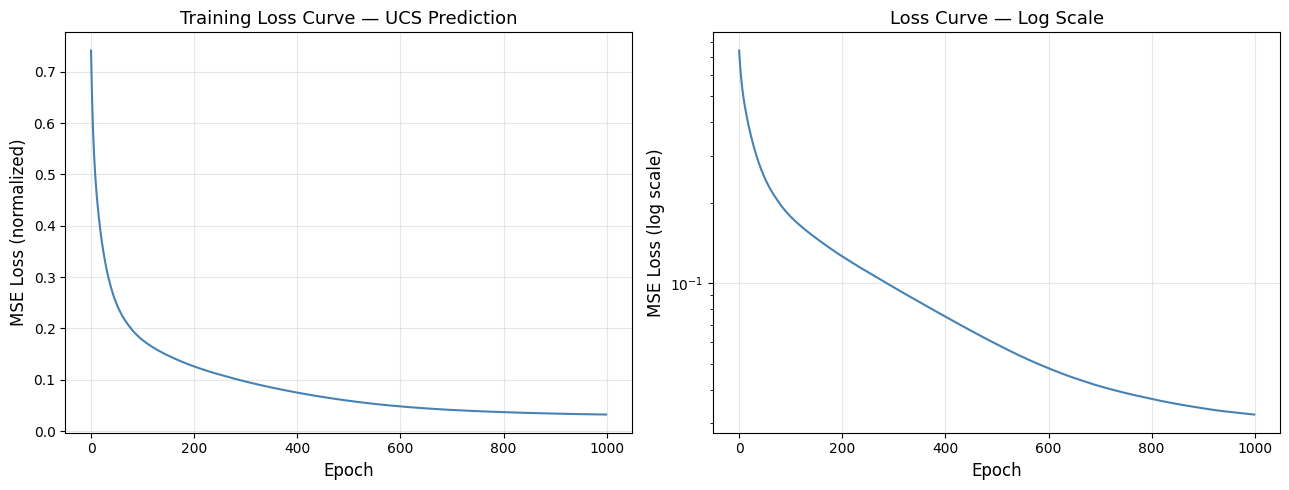

The loss decreases rapidly in early epochs, then converges.
This is healthy training behavior — the network is learning.


In [9]:
# ───────────────────────────────────────────────────────
# VISUALIZE THE LOSS CURVE
# ───────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Full loss curve
axes[0].plot(loss_history, color='steelblue', linewidth=1.5)
axes[0].set_xlabel('Epoch', fontsize=12)
axes[0].set_ylabel('MSE Loss (normalized)', fontsize=12)
axes[0].set_title('Training Loss Curve — UCS Prediction', fontsize=13)
axes[0].grid(True, alpha=0.3)

# Log scale for detail
axes[1].plot(loss_history, color='steelblue', linewidth=1.5)
axes[1].set_yscale('log')
axes[1].set_xlabel('Epoch', fontsize=12)
axes[1].set_ylabel('MSE Loss (log scale)', fontsize=12)
axes[1].set_title('Loss Curve — Log Scale', fontsize=13)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("The loss decreases rapidly in early epochs, then converges.")
print("This is healthy training behavior — the network is learning.")

---

## Part 9: Evaluate Predictions

Let's see how well our from-scratch neural network predicts UCS.

Model Performance:
  R² score: 0.9678
  RMSE:     7.97 kPa



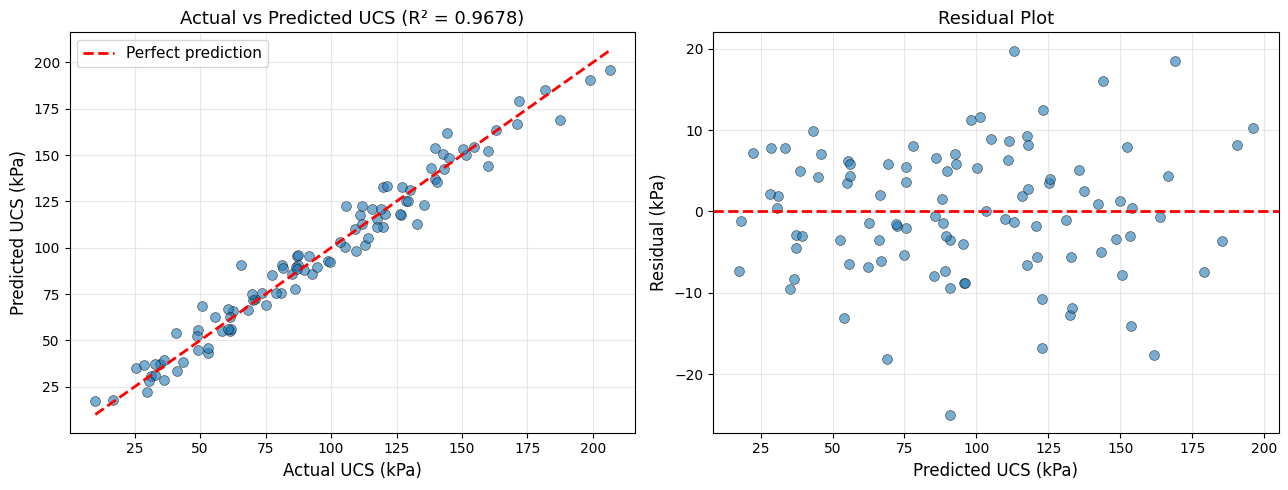

Points near the red line = good predictions.
Random residuals = model is not systematically biased.


In [10]:
# ───────────────────────────────────────────────────────
# EVALUATE — Compare predictions vs actual UCS values
# ───────────────────────────────────────────────────────

# Final predictions (de-normalized)
_, _, _, y_pred_norm = forward(X_norm, W1, b1, W2, b2)
y_pred_actual = y_pred_norm * y_std + y_mean  # back to kPa

# R-squared
ss_res = np.sum((y - y_pred_actual) ** 2)
ss_tot = np.sum((y - y.mean()) ** 2)
r_squared = 1 - ss_res / ss_tot

# RMSE in kPa
rmse = np.sqrt(np.mean((y - y_pred_actual) ** 2))

print(f"Model Performance:")
print(f"  R² score: {r_squared:.4f}")
print(f"  RMSE:     {rmse:.2f} kPa")
print()

# Plot actual vs predicted
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Scatter plot
axes[0].scatter(y, y_pred_actual, alpha=0.6, edgecolors='k', linewidth=0.5, s=50)
min_val = min(y.min(), y_pred_actual.min())
max_val = max(y.max(), y_pred_actual.max())
axes[0].plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='Perfect prediction')
axes[0].set_xlabel('Actual UCS (kPa)', fontsize=12)
axes[0].set_ylabel('Predicted UCS (kPa)', fontsize=12)
axes[0].set_title(f'Actual vs Predicted UCS (R² = {r_squared:.4f})', fontsize=13)
axes[0].legend(fontsize=11)
axes[0].grid(True, alpha=0.3)

# Residual plot
residuals = (y - y_pred_actual).flatten()
axes[1].scatter(y_pred_actual, residuals, alpha=0.6, edgecolors='k', linewidth=0.5, s=50)
axes[1].axhline(y=0, color='r', linewidth=2, linestyle='--')
axes[1].set_xlabel('Predicted UCS (kPa)', fontsize=12)
axes[1].set_ylabel('Residual (kPa)', fontsize=12)
axes[1].set_title('Residual Plot', fontsize=13)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Points near the red line = good predictions.")
print("Random residuals = model is not systematically biased.")

In [11]:
# ───────────────────────────────────────────────────────
# SAMPLE PREDICTIONS TABLE
# ───────────────────────────────────────────────────────

print(f"{'Sample':>6} {'N_value':>8} {'Depth':>6} {'WC(%)':>6} │ {'Actual':>10} {'Predicted':>10} {'Error':>8}")
print("─" * 64)
for i in range(15):
    err = y_pred_actual[i, 0] - y[i, 0]
    print(f"{i+1:6d} {X[i,0]:8.1f} {X[i,1]:6.1f} {X[i,2]:6.1f} │ "
          f"{y[i,0]:10.1f} {y_pred_actual[i,0]:10.1f} {err:+8.1f} kPa")

Sample  N_value  Depth  WC(%) │     Actual  Predicted    Error
────────────────────────────────────────────────────────────────
     1     18.1    1.6   32.5 │       58.5       54.9     -3.6 kPa
     2     38.3   13.1   12.9 │      181.6      185.3     +3.7 kPa
     3     30.6    7.0   15.7 │      160.1      144.0    -16.0 kPa
     4     26.0   10.7   41.4 │       92.6       86.1     -6.6 kPa
     5     10.5   18.2   31.2 │       50.7       68.8    +18.1 kPa
     6     10.5    5.7   10.3 │       81.0       75.5     -5.5 kPa
     7      7.0    8.8   13.6 │       62.5       66.1     +3.5 kPa
     8     35.3   15.4   33.2 │      151.3      150.1     -1.3 kPa
     9     26.0    5.3   10.2 │      127.2      132.8     +5.6 kPa
    10     29.8    2.5   15.6 │      130.1      131.2     +1.1 kPa
    11      5.7    6.5   29.2 │       34.5       37.4     +2.9 kPa
    12     38.9    4.1   34.2 │      139.8      137.2     -2.5 kPa
    13     34.1   18.7   32.8 │      138.1      143.1     +5.0 kPa
 

---

## Practice Exercises

### Exercise 1: Change Hidden Layer Size
Try `n_hidden = 4` and `n_hidden = 16`. How does performance change? Is bigger always better?

### Exercise 2: Use Sigmoid Instead of ReLU
Replace `relu` with `sigmoid` in the forward and backward passes. Compare the loss curves.

### Exercise 3: Learning Rate Experiment
Try `lr = 0.001`, `0.01`, `0.1`, and `0.5`. Plot all four loss curves on one graph.

In [12]:
# EXERCISE 1: Change hidden layer size
# n_hidden = 4   # try smaller
# n_hidden = 16  # try larger
# Re-run the training loop and compare R² values

# EXERCISE 2: Use sigmoid activation
# Modify the forward() function to use sigmoid instead of relu
# Modify backward() to use sigmoid_derivative instead of relu_derivative
# Hint: sigmoid_derivative takes the activated value (a1), not the pre-activation (z1)

# EXERCISE 3: Learning rate comparison
# learning_rates = [0.001, 0.01, 0.1, 0.5]
# for lr in learning_rates:
#     # Reset weights, train, store loss_history
#     # Plot all curves on one figure
#     pass

---

## Key Takeaways

1. **A neural network is just matrix multiplications + non-linear activations.** Each layer computes `z = X @ W + b`, then passes through an activation function.

2. **ReLU is the default hidden-layer activation** — it is simple, fast, and avoids the vanishing gradient problem that plagues sigmoid in deep networks.

3. **Backpropagation is the chain rule applied layer by layer.** We compute `dL/dW` for each weight matrix, working backwards from the loss.

4. **Gradient descent updates weights in the direction that reduces loss.** The learning rate controls the step size — too large diverges, too small converges slowly.

5. **Data normalization is essential.** Without it, features on different scales (N-value: 5–40, depth: 1–20) create unbalanced gradients.

6. **The loss curve reveals training health.** Smooth decrease = good. Oscillation = learning rate too high. Flat = learning rate too low or network too small.

---

## How This Connects to ML

| Today (NN from Scratch) | Framework Equivalent |
|-------------------------|---------------------|
| `W1 = np.random.randn(...)` | `nn.Linear(3, 8)` auto-initializes weights |
| `z1 = X @ W1 + b1` | `self.layer1 = nn.Linear(3, 8)` does this |
| `relu(z1)` | `F.relu(z1)` or `nn.ReLU()` |
| Manual backprop chain rule | `loss.backward()` — PyTorch autograd |
| `W1 -= lr * dW1` | `optimizer.step()` |
| `mse_loss()` | `nn.MSELoss()` |

**Tomorrow we start using PyTorch** — which automates everything we did by hand today. Understanding the internals helps you debug and design better architectures.

---

*Day 061 of 100 — We built a brain from scratch with nothing but NumPy and linear algebra!*